In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
path = '/content/drive/MyDrive/ML2026/PRAKTIKUM5'
os.makedirs(path + '/MODELS', exist_ok=True)
os.makedirs(path + '/REPORT', exist_ok=True)
print(os.listdir(path + '/DATA'))

Mounted at /content/drive
['dataset_iris.csv', 'stunting_wasting_dataset.csv']


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [5]:
df = pd.read_csv(path + '/DATA/stunting_wasting_dataset.csv')
df.head()

,Jenis Kelamin,Umur (bulan),Tinggi Badan (cm),Berat Badan (kg),Stunting,Wasting
0,Laki-laki,19,91.6,13.3,Tall,Risk of Overweight
1,Laki-laki,20,77.7,8.5,Stunted,Underweight
2,Laki-laki,10,79.0,10.3,Normal,Risk of Overweight
3,Perempuan,2,50.3,8.3,Severely Stunted,Risk of Overweight
4,Perempuan,5,56.4,10.9,Severely Stunted,Risk of Overweight


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Jenis Kelamin      100000 non-null  object 
 1   Umur (bulan)       100000 non-null  int64  
 2   Tinggi Badan (cm)  100000 non-null  float64
 3   Berat Badan (kg)   100000 non-null  float64
 4   Stunting           100000 non-null  object 
 5   Wasting            100000 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 4.6+ MB


In [7]:
df.isnull().sum()

,0
Jenis Kelamin,0
Umur (bulan),0
Tinggi Badan (cm),0
Berat Badan (kg),0
Stunting,0
Wasting,0


In [8]:
print("Duplikat sebelum dihapus:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplikat setelah dihapus:", df.duplicated().sum())

Duplikat sebelum dihapus: 7308
Duplikat setelah dihapus: 0


In [9]:
df = df.rename(columns={
    'Jenis Kelamin': 'jenis_kelamin',
    'Umur (bulan)': 'umur_bulan',
    'Tinggi Badan (cm)': 'tinggi_cm',
    'Berat Badan (kg)': 'berat_kg',
    'Stunting': 'stunting',
    'Wasting': 'wasting'
})
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 92692 entries, 0 to 99997
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   jenis_kelamin  92692 non-null  object 
 1   umur_bulan     92692 non-null  int64  
 2   tinggi_cm      92692 non-null  float64
 3   berat_kg       92692 non-null  float64
 4   stunting       92692 non-null  object 
 5   wasting        92692 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 5.0+ MB


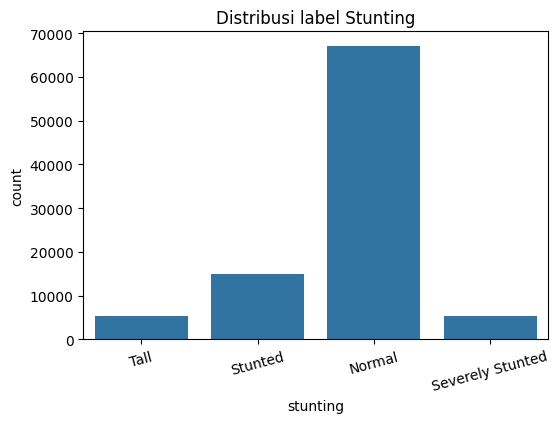

In [10]:
plt.figure(figsize=(6,4))
sns.countplot(x='stunting', data=df)
plt.title('Distribusi label Stunting')
plt.xticks(rotation=15)
plt.savefig(path + '/REPORT/distribusi_stunting.png', bbox_inches='tight')
plt.show()

In [11]:
# mapping label -> kode untuk target
stunting_cat = df['stunting'].astype('category')
stunting_classes = list(stunting_cat.cat.categories)   # urutan kelas
df['stunting'] = stunting_cat.cat.codes                # y numerik

# fitur kategorikal lain -> kode juga
for col in ['jenis_kelamin', 'wasting']:
    if col in df.columns:
        df[col] = df[col].astype('category').cat.codes

print(stunting_classes)
df.head()

['Normal', 'Severely Stunted', 'Stunted', 'Tall']


,jenis_kelamin,umur_bulan,tinggi_cm,berat_kg,stunting,wasting
0,0,19,91.6,13.3,3,1
1,0,20,77.7,8.5,2,3
2,0,10,79.0,10.3,0,1
3,1,2,50.3,8.3,1,1
4,1,5,56.4,10.9,1,1


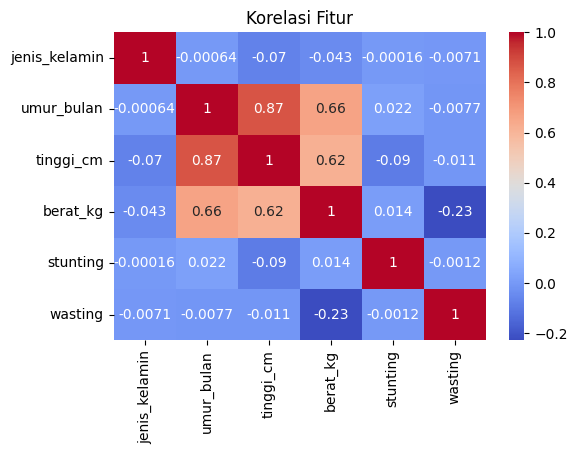

In [12]:
plt.figure(figsize=(6,4))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Korelasi Fitur')
plt.savefig(path + '/REPORT/korelasi_stunting.png', bbox_inches='tight')
plt.show()

In [13]:
feature_cols = ['umur_bulan', 'tinggi_cm', 'berat_kg', 'wasting']
X = df[feature_cols]
y = df['stunting']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
len(X_train), len(X_test)

(74153, 18539)

In [14]:
dt = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=42
)
dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [15]:
y_pred = dt.predict(X_test)

print("Akurasi:", round(accuracy_score(y_test, y_pred)*100, 2), "%")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(
    y_test, y_pred, target_names=stunting_classes
))

Akurasi: 77.67 %

Confusion Matrix:
 [[12901     0   481    29]
 [  587    25   455     0]
 [ 1653     0  1355     0]
 [  935     0     0   118]]

Classification Report:
                   precision    recall  f1-score   support

          Normal       0.80      0.96      0.88     13411
Severely Stunted       1.00      0.02      0.05      1067
         Stunted       0.59      0.45      0.51      3008
            Tall       0.80      0.11      0.20      1053

        accuracy                           0.78     18539
       macro avg       0.80      0.39      0.41     18539
    weighted avg       0.78      0.78      0.73     18539



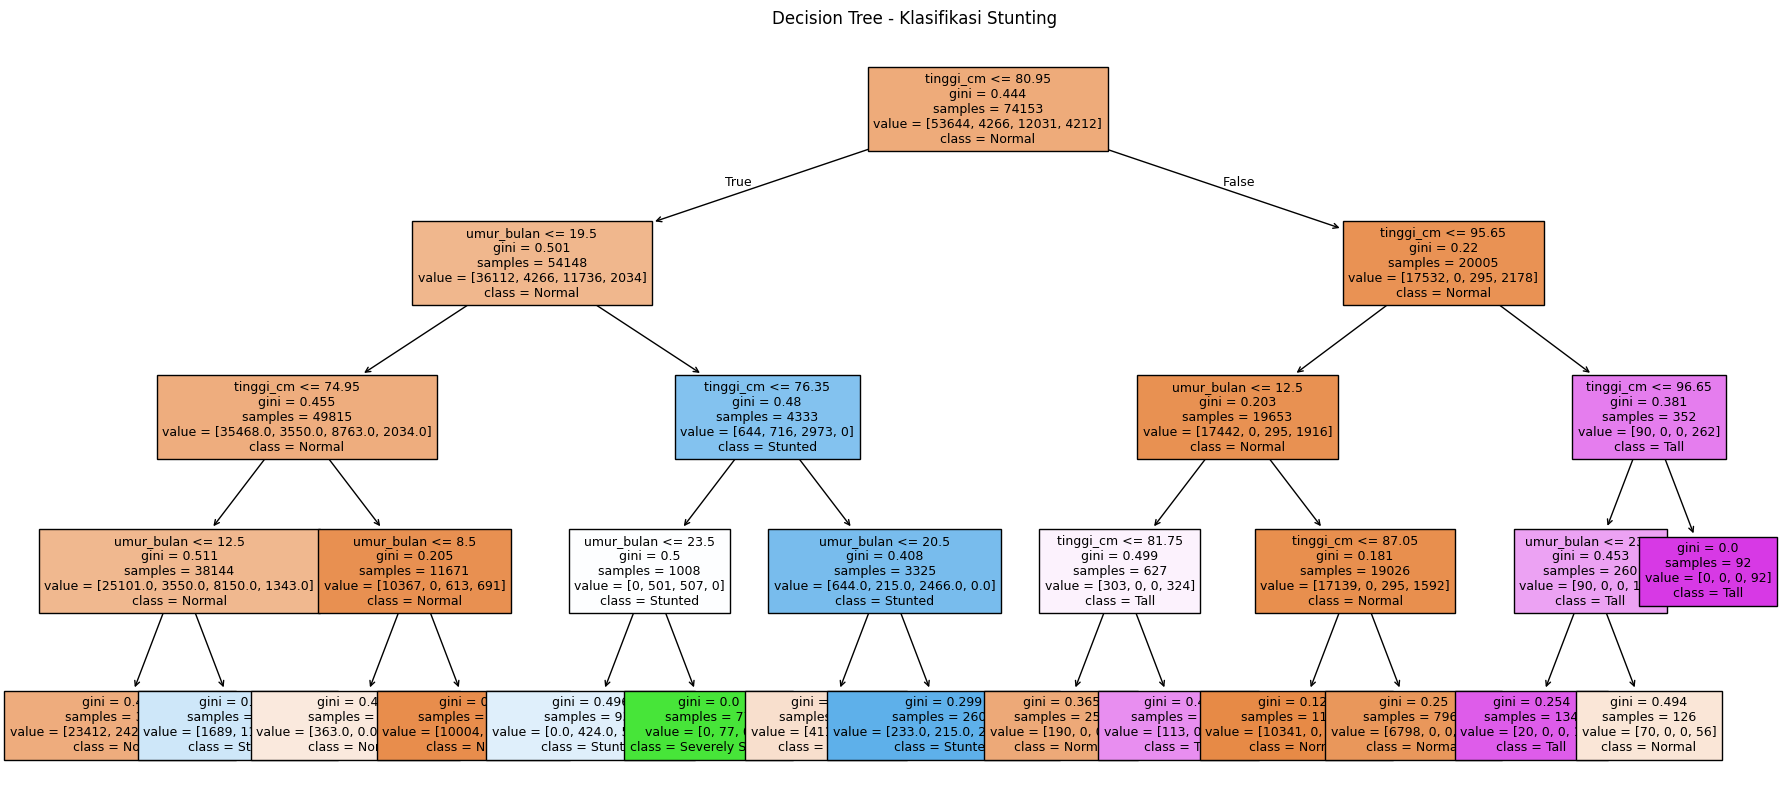

In [16]:
plt.figure(figsize=(22,10))
plot_tree(
    dt,
    feature_names=feature_cols,
    class_names=stunting_classes,
    filled=True,
    fontsize=9
)
plt.title("Decision Tree - Klasifikasi Stunting")
plt.savefig(path + '/REPORT/tree_stunting.png', bbox_inches='tight', dpi=150)
plt.show()

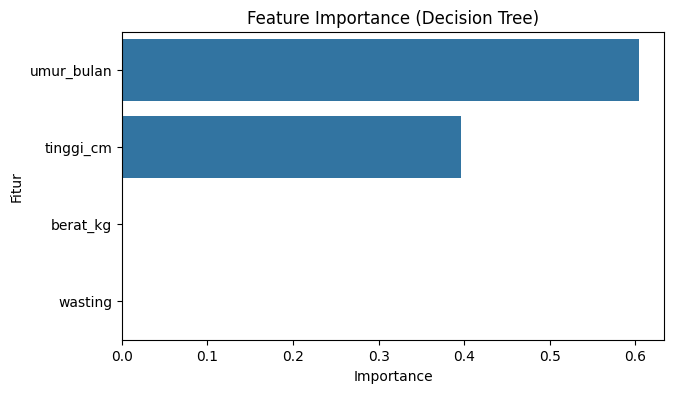

,0
umur_bulan,0.603752
tinggi_cm,0.396248
berat_kg,0.000000
wasting,0.000000


In [17]:
imp = pd.Series(dt.feature_importances_, index=feature_cols).sort_values(ascending=False)
plt.figure(figsize=(7,4))
sns.barplot(x=imp, y=imp.index)
plt.title("Feature Importance (Decision Tree)")
plt.xlabel("Importance")
plt.ylabel("Fitur")
plt.savefig(path + '/REPORT/feature_importance_stunting.png', bbox_inches='tight')
plt.show()

imp

In [18]:
scores = {}
for d in range(2, 9):
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    m.fit(X_train, y_train)
    scores[d] = accuracy_score(y_test, m.predict(X_test))

print(scores)
best_d = max(scores, key=scores.get)
print("Best max_depth:", best_d, "| Acc:", round(scores[best_d]*100, 2), "%")

{2: 0.7571605803980798, 3: 0.757106640056098, 4: 0.7766869841954798, 5: 0.7840228707050003, 6: 0.8174119423917148, 7: 0.8237769027455634, 8: 0.8422244997033281}
Best max_depth: 8 | Acc: 84.22 %


In [19]:
dt_best = DecisionTreeClassifier(criterion='gini', max_depth=best_d, random_state=42)
dt_best.fit(X_train, y_train)
print("Akurasi model final:", round(accuracy_score(y_test, dt_best.predict(X_test))*100, 2), "%")

joblib.dump(dt_best, path + '/MODELS/dt_stunting.joblib')
print("Model tersimpan di MODELS/")

Akurasi model final: 84.22 %
Model tersimpan di MODELS/


BAGIAN B — Tugas Praktikum Mandir

In [20]:
# sep=None biar otomatis deteksi pemisah (koma / titik koma)
iris = pd.read_csv(path + '/DATA/dataset_iris.csv', sep=None, engine='python')
iris.columns = iris.columns.str.strip()
iris.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [21]:
iris.info()
print("\nMissing value:\n", iris.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Missing value:
 Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


In [22]:
# buang kolom Id: cuma nomor urut, bukan ciri bunga
iris = iris.drop(columns=[c for c in iris.columns if c.lower() == 'id'])

target_col = iris.columns[-1]   # kolom Species
feature_cols_iris = [c for c in iris.columns if c != target_col]

# jaga-jaga kalau angkanya pakai koma desimal (format Excel Indonesia)
for c in feature_cols_iris:
    if iris[c].dtype == object:
        iris[c] = pd.to_numeric(iris[c].str.replace(',', '.'), errors='coerce')

print("Duplikat sebelum dihapus:", iris.duplicated().sum())
iris = iris.drop_duplicates().reset_index(drop=True)
print("Jumlah data setelah dibersihkan:", len(iris))
print("Fitur:", feature_cols_iris, "| Target:", target_col)

Duplikat sebelum dihapus: 3
Jumlah data setelah dibersihkan: 147
Fitur: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm'] | Target: Species


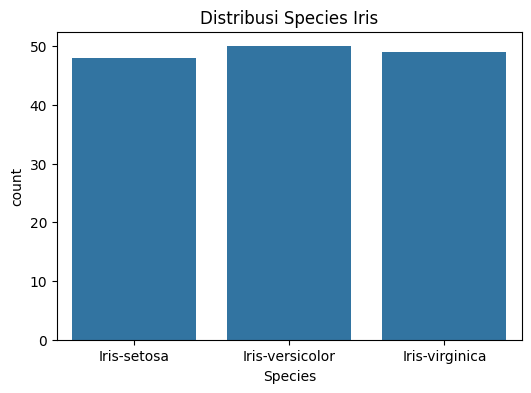

In [23]:
plt.figure(figsize=(6,4))
sns.countplot(x=target_col, data=iris)
plt.title('Distribusi Species Iris')
plt.savefig(path + '/REPORT/distribusi_iris.png', bbox_inches='tight')
plt.show()

In [24]:
species_cat = iris[target_col].astype('category')
species_classes = list(species_cat.cat.categories)
iris['species_code'] = species_cat.cat.codes

print(species_classes)
iris.head()

['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,species_code
0,5.1,3.5,1.4,0.2,Iris-setosa,0
1,4.9,3.0,1.4,0.2,Iris-setosa,0
2,4.7,3.2,1.3,0.2,Iris-setosa,0
3,4.6,3.1,1.5,0.2,Iris-setosa,0
4,5.0,3.6,1.4,0.2,Iris-setosa,0


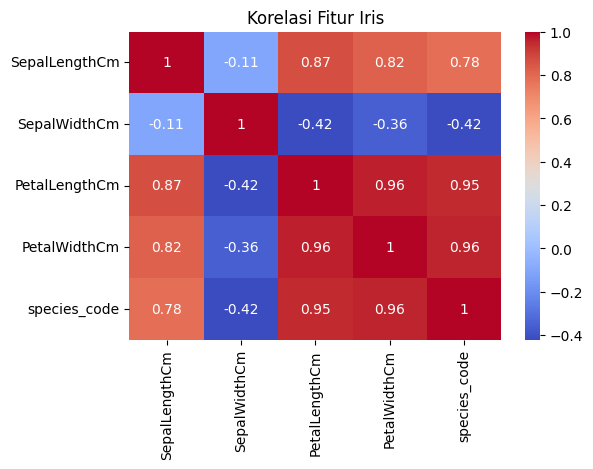

In [25]:
plt.figure(figsize=(6,4))
sns.heatmap(iris[feature_cols_iris + ['species_code']].corr(), annot=True, cmap='coolwarm')
plt.title('Korelasi Fitur Iris')
plt.savefig(path + '/REPORT/korelasi_iris.png', bbox_inches='tight')
plt.show()

In [26]:
X_i = iris[feature_cols_iris]
y_i = iris['species_code']

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_i, y_i,
    test_size=0.2,
    random_state=42,
    stratify=y_i
)
len(Xi_train), len(Xi_test)

(117, 30)

In [27]:
dt_iris = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)
dt_iris.fit(Xi_train, yi_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

Akurasi: 96.67 %

Classification Report:
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



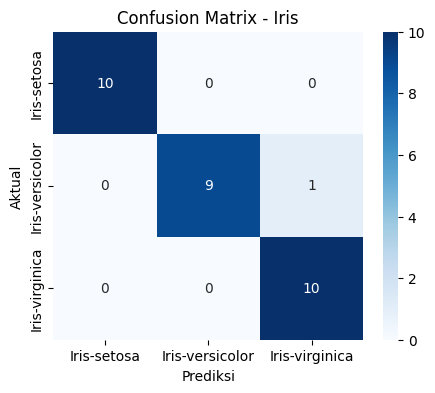

In [28]:
yi_pred = dt_iris.predict(Xi_test)

print("Akurasi:", round(accuracy_score(yi_test, yi_pred)*100, 2), "%")
print("\nClassification Report:\n", classification_report(
    yi_test, yi_pred, target_names=species_classes
))

cm = confusion_matrix(yi_test, yi_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=species_classes, yticklabels=species_classes)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - Iris')
plt.savefig(path + '/REPORT/confusion_matrix_iris.png', bbox_inches='tight')
plt.show()

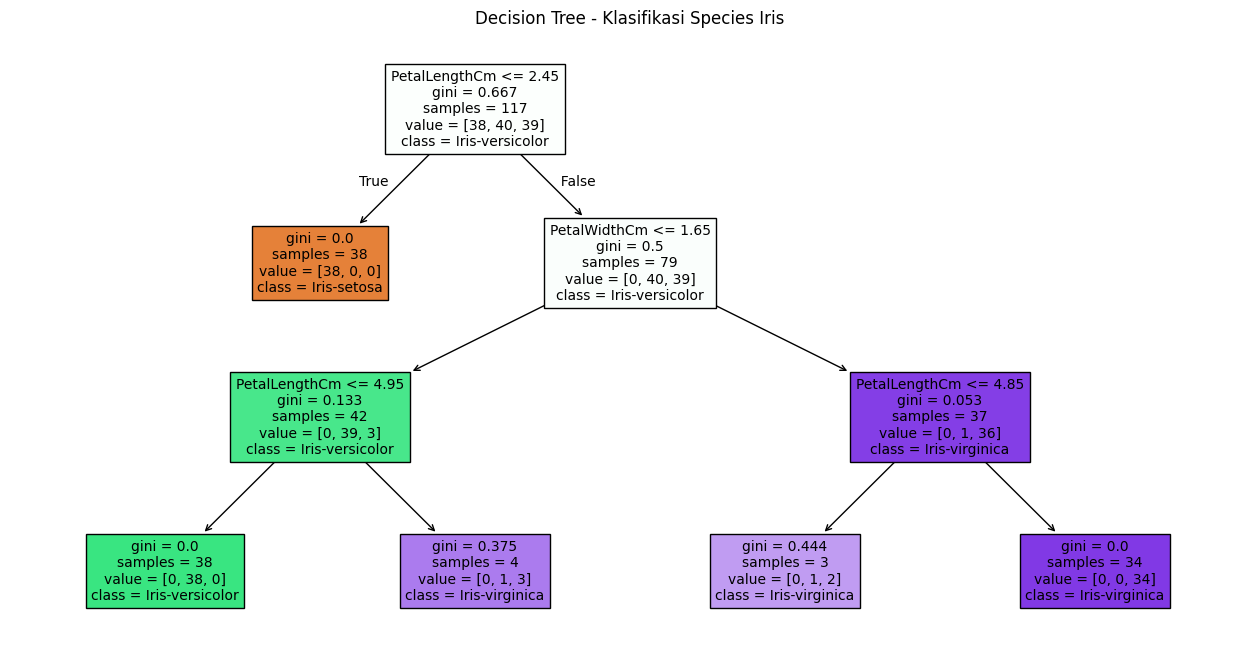

In [29]:
plt.figure(figsize=(16,8))
plot_tree(
    dt_iris,
    feature_names=feature_cols_iris,
    class_names=species_classes,
    filled=True,
    fontsize=10
)
plt.title("Decision Tree - Klasifikasi Species Iris")
plt.savefig(path + '/REPORT/tree_iris.png', bbox_inches='tight', dpi=150)
plt.show()

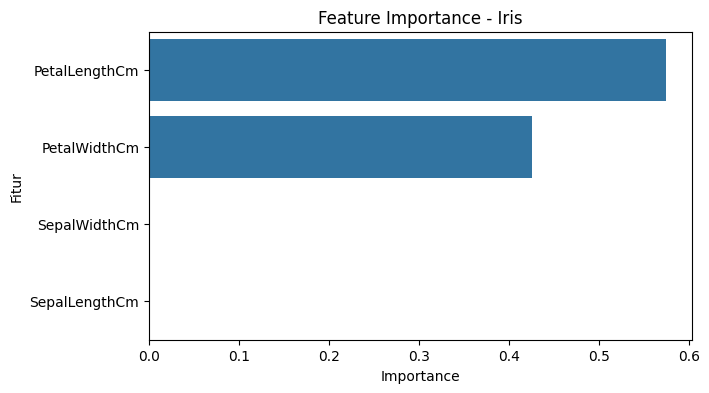

,0
PetalLengthCm,0.574498
PetalWidthCm,0.425502
SepalWidthCm,0.000000
SepalLengthCm,0.000000


In [30]:
imp_iris = pd.Series(dt_iris.feature_importances_, index=feature_cols_iris).sort_values(ascending=False)
plt.figure(figsize=(7,4))
sns.barplot(x=imp_iris, y=imp_iris.index)
plt.title("Feature Importance - Iris")
plt.xlabel("Importance")
plt.ylabel("Fitur")
plt.savefig(path + '/REPORT/feature_importance_iris.png', bbox_inches='tight')
plt.show()

imp_iris

In [31]:
hasil_depth = []
for d in range(1, 9):
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    m.fit(Xi_train, yi_train)
    hasil_depth.append({
        'max_depth': d,
        'acc_train': round(accuracy_score(yi_train, m.predict(Xi_train))*100, 2),
        'acc_test': round(accuracy_score(yi_test, m.predict(Xi_test))*100, 2)
    })
pd.DataFrame(hasil_depth)

,max_depth,acc_train,acc_test
0,1,66.67,66.67
1,2,96.58,93.33
2,3,98.29,96.67
3,4,99.15,93.33
4,5,100.00,93.33
5,6,100.00,93.33
6,7,100.00,93.33
7,8,100.00,93.33


In [32]:
hasil_uji = Xi_test.copy()
hasil_uji['Aktual'] = [species_classes[i] for i in yi_test]
hasil_uji['Prediksi'] = [species_classes[i] for i in yi_pred]
hasil_uji['Benar'] = hasil_uji['Aktual'] == hasil_uji['Prediksi']

print("Prediksi benar:", hasil_uji['Benar'].sum(), "dari", len(hasil_uji), "data testing")
hasil_uji

Prediksi benar: 29 dari 30 data testing


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Aktual,Prediksi,Benar
61,6.1,2.9,4.7,1.4,Iris-versicolor,Iris-versicolor,True
82,5.4,3.0,4.5,1.5,Iris-versicolor,Iris-versicolor,True
139,6.9,3.1,5.1,2.3,Iris-virginica,Iris-virginica,True
42,5.1,3.8,1.9,0.4,Iris-setosa,Iris-setosa,True
144,6.5,3.0,5.2,2.0,Iris-virginica,Iris-virginica,True
75,6.7,3.0,5.0,1.7,Iris-versicolor,Iris-virginica,False
54,6.3,3.3,4.7,1.6,Iris-versicolor,Iris-versicolor,True
38,5.0,3.5,1.3,0.3,Iris-setosa,Iris-setosa,True
136,6.0,3.0,4.8,1.8,Iris-virginica,Iris-virginica,True
125,6.1,3.0,4.9,1.8,Iris-virginica,Iris-virginica,True


In [33]:
joblib.dump(dt_iris, path + '/MODELS/dt_iris.joblib')
print("Model tersimpan di MODELS/")

Model tersimpan di MODELS/
